In [90]:
#import sys 

#!{sys.executable} -m pip install pandas numpy matplotlib scikit-learn xgboost

In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [92]:
df = pd.read_csv("diabetes_prediction_dataset.csv")
df = df.drop_duplicates()

df.info()

<class 'pandas.DataFrame'>
Index: 96146 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   gender               96146 non-null  str    
 1   age                  96146 non-null  float64
 2   hypertension         96146 non-null  int64  
 3   heart_disease        96146 non-null  int64  
 4   smoking_history      96146 non-null  str    
 5   bmi                  96146 non-null  float64
 6   HbA1c_level          96146 non-null  float64
 7   blood_glucose_level  96146 non-null  int64  
 8   diabetes             96146 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 7.3 MB


In [93]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [94]:
feature_list = list(df.columns)
print(feature_list)

continuous_feature = ["age", "bmi","HbA1c_level", "blood_glucose_level"]

['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']


**Data Checking**

Checking how many types of countable values are in different feature.

If a feature is obvious remove it

In [95]:
value_types = {}

for df_column in [x for x in feature_list if x not in continuous_feature]:
  value_types[df_column] = {}
  for elem in df[df_column]:
    if elem in value_types[df_column]:
      value_types[df_column][elem] += 1
    else:
      value_types[df_column][elem] = 1

value_types

{'gender': {'Female': 56161, 'Male': 39967, 'Other': 18},
 'hypertension': {0: 88685, 1: 7461},
 'heart_disease': {1: 3923, 0: 92223},
 'smoking_history': {'never': 34398,
  'No Info': 32887,
  'current': 9197,
  'former': 9299,
  'ever': 3998,
  'not current': 6367},
 'diabetes': {0: 87664, 1: 8482}}

**Converting gender to numerical data**

In [96]:
#Females = 0 , Male = 1, Other = 2
mapping = {"Female": 0, "Male": 1, "Other": 2}
df["gender"] = df["gender"].map(mapping)




df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,0,80.0,0,1,never,25.19,6.6,140,0
1,0,54.0,0,0,No Info,27.32,6.6,80,0
2,1,28.0,0,0,never,27.32,5.7,158,0
3,0,36.0,0,0,current,23.45,5.0,155,0
4,1,76.0,1,1,current,20.14,4.8,155,0


In [97]:
df["gender"].isna().sum()

np.int64(0)

**Age Distribution**

Text(0.5, 1.0, 'Age distribution')

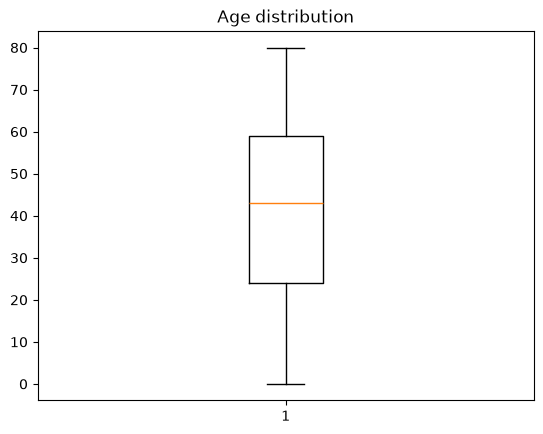

In [98]:
plt.boxplot(df["age"])
plt.title("Age distribution")

**Bmi Distribution**


Text(0, 0.5, 'Number of patients')

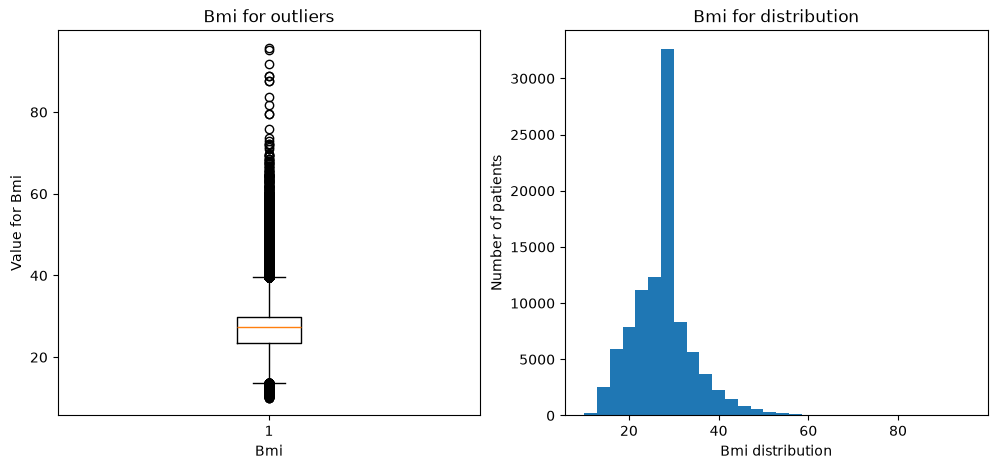

In [99]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.boxplot(df["bmi"])
ax1.set_title("Bmi for outliers")
ax1.set_xlabel("Bmi")
ax1.set_ylabel("Value for Bmi")

ax2.hist(df["bmi"], bins = 30)
ax2.set_title("Bmi for distribution")
ax2.set_xlabel("Bmi distribution")
ax2.set_ylabel("Number of patients")


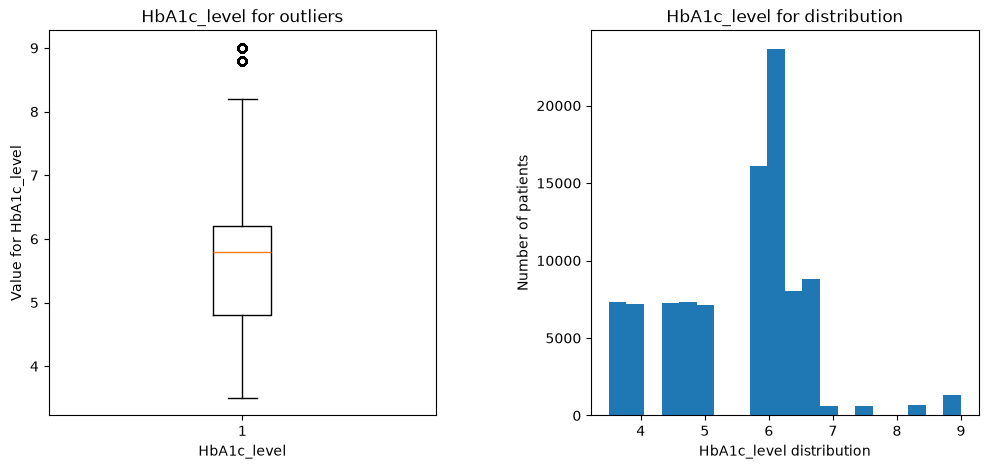

In [100]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.boxplot(df["HbA1c_level"])
ax1.set_title("HbA1c_level for outliers")
ax1.set_xlabel("HbA1c_level")
ax1.set_ylabel("Value for HbA1c_level")

ax2.hist(df["HbA1c_level"], bins = 20)
ax2.set_title("HbA1c_level for distribution")
ax2.set_xlabel("HbA1c_level distribution")
ax2.set_ylabel("Number of patients")

plt.subplots_adjust(wspace=0.4)

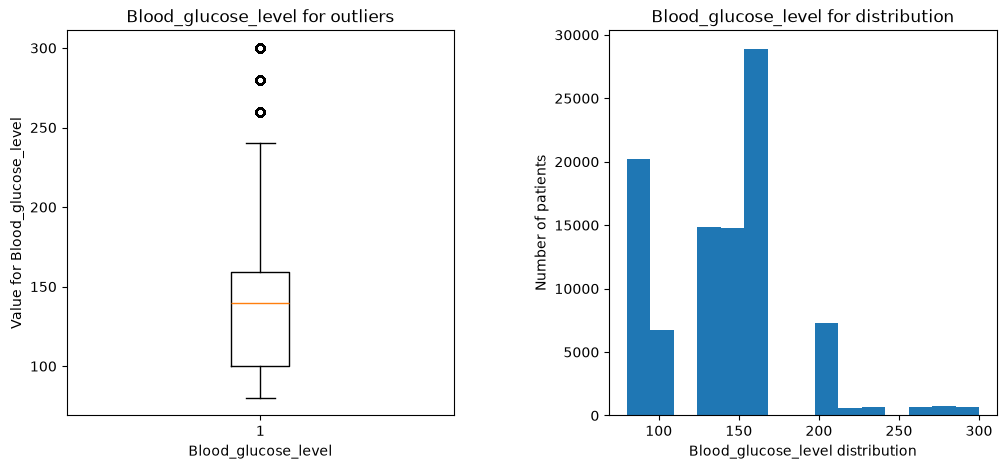

In [101]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.boxplot(df["blood_glucose_level"])
ax1.set_title("Blood_glucose_level for outliers")
ax1.set_xlabel("Blood_glucose_level")
ax1.set_ylabel("Value for Blood_glucose_level")

ax2.hist(df["blood_glucose_level"], bins = 15)
ax2.set_title("Blood_glucose_level for distribution")
ax2.set_xlabel("Blood_glucose_level distribution")
ax2.set_ylabel("Number of patients")

plt.subplots_adjust(wspace=0.4)



**Final test to make sure there are no missing values**

In [102]:
df.isnull().values.any()

np.False_

**Dataset Splits**

In [103]:
from sklearn.model_selection import train_test_split

X, y = df.drop(columns = "diabetes"), df["diabetes"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.3, stratify=y, random_state=42)

print(len(X_train), len(X_test))
y_train.value_counts(normalize=True)

67302 28844


diabetes
0    0.911786
1    0.088214
Name: proportion, dtype: float64

**Feature Selection**

Using correlation coefficent to find the mose correlating feature in the dataset

In [158]:
correlation_train_dataset = X_train.copy()
correlation_train_dataset["diabetes"] = y_train.copy()

#Using numerical data to look for correlation
numerical_data = correlation_train_dataset.drop(columns = "smoking_history")
numerical_data.info()

numerical_data.corr()["diabetes"].drop("diabetes").sort_values(ascending=False)

<class 'pandas.DataFrame'>
Index: 67302 entries, 70233 to 10061
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   gender               67302 non-null  int64  
 1   age                  67302 non-null  float64
 2   hypertension         67302 non-null  int64  
 3   heart_disease        67302 non-null  int64  
 4   bmi                  67302 non-null  float64
 5   HbA1c_level          67302 non-null  float64
 6   blood_glucose_level  67302 non-null  int64  
 7   diabetes             67302 non-null  int64  
dtypes: float64(3), int64(5)
memory usage: 6.6 MB


blood_glucose_level    0.423978
HbA1c_level            0.405584
age                    0.265517
bmi                    0.213501
hypertension           0.197227
heart_disease          0.174298
gender                 0.039709
Name: diabetes, dtype: float64

Mutual information classifier uses categorical features as well therfore includes the somking history

In [153]:
from sklearn.feature_selection import mutual_info_classif

X_enc = pd.get_dummies(X_train, columns=["smoking_history"])
mi = pd.Series(mutual_info_classif(X_enc, y_train, random_state=42), index=X_enc.columns)
mi.sort_values(ascending=False)

HbA1c_level                    0.134278
blood_glucose_level            0.116053
age                            0.041748
bmi                            0.023015
hypertension                   0.013884
smoking_history_No Info        0.011812
heart_disease                  0.009346
gender                         0.006871
smoking_history_never          0.004262
smoking_history_former         0.004176
smoking_history_current        0.001311
smoking_history_ever           0.000000
smoking_history_not current    0.000000
dtype: float64

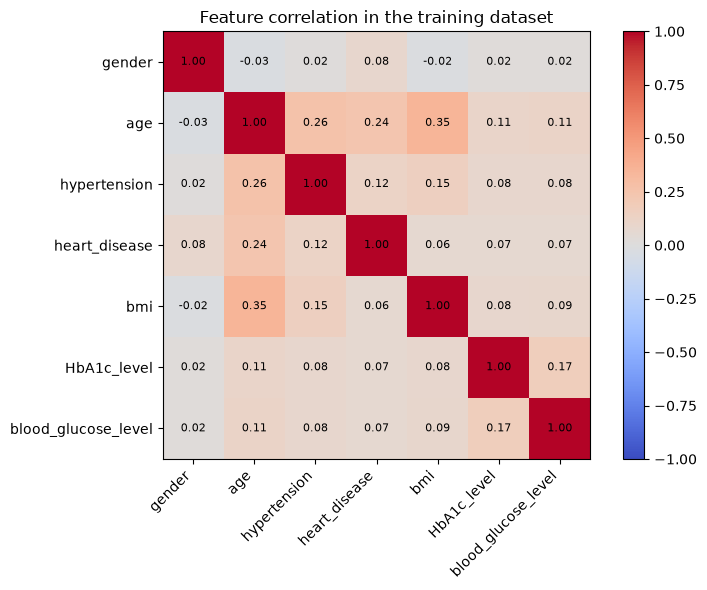

In [155]:
import matplotlib.pyplot as plt

corr = X_train.select_dtypes("number").corr()
plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(); plt.title("Feature correlation in the training dataset"); plt.tight_layout()

**Cross-validation**

In [104]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier

**Preprocessing**

Turn the categorical smoking history into numerical data using OneHotEncoder for the cross validation algorithm

In [105]:
category_column = ["smoking_history"]

preprocessing = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), category_column)], remainder = "passthrough")

preprocessing

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. 

**Weights**

Weighing the positive and negative classes diefferently due to class imbalance

In [106]:
weight = (y_train == 0).sum() / (y_train == 1).sum()
weight

np.float64(10.336028297119757)

Create a pipeline for the crossvalidation to use

In [107]:
model = Pipeline([("preprocessing", preprocessing), ("classification", XGBClassifier(scale_pos_weight = weight, n_estimators = 300, max_depth = 4, learning_rate = 0.05))])
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classification', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If 

**Cross-validation and evaluation**

Implement the scikit-learn StratifiedKFold cross validation then evaluate based on avg_prec, recall, f1_score

In [108]:
cross_validation = StratifiedKFold(n_splits = 3, shuffle = True, random_state = 42)

result = cross_validate(model, X_train, y_train, cv = cross_validation, scoring = ["average_precision", "recall", "f1"])


for k, v in result.items():
  if k.startswith("test_"):
    print(f"{k} for 3 splits: {[float("%.3f"%x.item()) for x in v]}, mean: {v.mean():.3f}, standard deviation: {v.std():.3f}")
    #print(f"{k}: {v.mean():.3f} ± {v.std():.3f}")

test_average_precision for 3 splits: [0.886, 0.891, 0.89], mean: 0.889, standard deviation: 0.002
test_recall for 3 splits: [0.933, 0.923, 0.92], mean: 0.925, standard deviation: 0.006
test_f1 for 3 splits: [0.636, 0.641, 0.616], mean: 0.631, standard deviation: 0.011


**Dummy Baseline**

In [147]:

from sklearn.dummy import DummyClassifier


Xy_trainvalid = df.copy()
feature_columns = []
label_column = "diabetes"


baselines = ["most_frequent", "stratified", "uniform"]
strategy_results = []

for strategy in baselines:
  model = DummyClassifier(strategy=strategy, random_state = 42)
  model_result = cross_validate(model, X_train, y_train, cv = cross_validation, scoring = ["average_precision", "recall", "f1"])

  lines = [f"{strategy}:"]
  
  for k, v in model_result.items():
    if k.startswith("test_"):
        lines.append(f"{k} for 3 splits: {[round(float("%.5f"%x.item()), 5) for x in v]}, mean: {v.mean():.5f}, standard deviation: {v.std():.5f}")    

  strategy_results.append("\n".join(lines))

for elem in strategy_results:
   print(elem, "\n")

most_frequent:
test_average_precision for 3 splits: [0.08821, 0.08821, 0.08821], mean: 0.08821, standard deviation: 0.00000
test_recall for 3 splits: [0.0, 0.0, 0.0], mean: 0.00000, standard deviation: 0.00000
test_f1 for 3 splits: [0.0, 0.0, 0.0], mean: 0.00000, standard deviation: 0.00000 

stratified:
test_average_precision for 3 splits: [0.08851, 0.08906, 0.08901], mean: 0.08886, standard deviation: 0.00025
test_recall for 3 splits: [0.09197, 0.09752, 0.09702], mean: 0.09550, standard deviation: 0.00251
test_f1 for 3 splits: [0.09169, 0.09723, 0.09673], mean: 0.09521, standard deviation: 0.00250 

uniform:
test_average_precision for 3 splits: [0.08821, 0.08821, 0.08821], mean: 0.08821, standard deviation: 0.00000
test_recall for 3 splits: [0.49621, 0.49975, 0.49924], mean: 0.49840, standard deviation: 0.00156
test_f1 for 3 splits: [0.14861, 0.14967, 0.14952], mean: 0.14926, standard deviation: 0.00047 



**Advanced Models**

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

#Standardization for data to be bounded in [0,1]
preprocessing_standardization = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), category_column)], remainder = StandardScaler())


#Create Pipelines for the ML models avoiding test set leak into the training sets
ml_pipelines = {
  "log_reg" : Pipeline([("preprocessing", preprocessing_standardization), ("classification", LogisticRegression(class_weight="balanced", max_iter=3000))] )
}

ml_pipelines

{'log_reg': Pipeline(steps=[('preprocessing',
                  ColumnTransformer(remainder=StandardScaler(),
                                    transformers=[('cat',
                                                   OneHotEncoder(handle_unknown='ignore'),
                                                   ['smoking_history'])])),
                 ('classification',
                  LogisticRegression(class_weight='balanced', max_iter=3000))])}